## MLPI Textbook — Chapter 2 companion notebook

# A Tour of Classifiers on a Part-Sorting Conveyor

### Logistic regression, support vector machines, decision trees and k-nearest neighbours

---

Parts arrive on a conveyor in random order: **flat washers, hex nuts and flanged bushings**, all
in zinc-plated steel. Above the belt sits an inspection station — a camera that measures the
outer diameter and the hole, a laser line that measures height, and a load cell under a short
section of belt that weighs each part. At the end of the station a pneumatic diverter must push
each part into the right bin.

The station produces four numbers per part. A **classifier** turns those four numbers into one of
three bin decisions. This notebook builds four different classifiers for that job and, more
importantly, shows *how each one draws its decision boundary* — because that is what decides
whether it will work on your cell.

### What you will be able to do afterwards

1. Frame a sorting / inspection task as a supervised classification problem, and prepare the
   data correctly (stratified split, scaling fitted on the training set only).
2. Implement **logistic regression** with gradient descent from scratch, and read its output as a
   probability.
3. Explain the **maximum-margin** idea behind SVMs and use the **kernel trick** to solve a problem
   no straight line can solve (the reachable workspace of a robot arm).
4. Grow a **decision tree**, read its rules, and control its depth.
5. Use **k-nearest neighbours**, and see why it is useless without feature scaling.
6. Compare the four on the same held-out test set.

| § | topic |
|---|---|
| 1 | the data — a simulated inspection station |
| 2 | train/test split and standardisation |
| 3 | logistic regression, from scratch and with scikit-learn |
| 4 | support vector machines and kernels |
| 5 | decision trees |
| 6 | k-nearest neighbours |
| 7 | head-to-head comparison |

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

# plot style shared by every chapter of the book
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "font.size": 10, "legend.frameon": False,
})
BLUE, ORANGE, AQUA, YELLOW, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781"
CLASS_COLORS = [BLUE, ORANGE, AQUA]

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)


def savefig(name):
    """Save the current figure for the chapter text (figures/<name>.png)."""
    plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")

python       3.13.18
numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1


In [2]:
from matplotlib.colors import ListedColormap


def plot_decision_regions(X, y, classifier, ax=None, names=None, resolution=300,
                          test_idx=None, xlabel=None, ylabel=None):
    """Shade the region each class wins in a 2-feature plane and overlay the samples."""
    ax = ax or plt.gca()
    classes = np.unique(y)
    cmap = ListedColormap(CLASS_COLORS[:len(classes)])
    pad_x = 0.08 * np.ptp(X[:, 0]); pad_y = 0.08 * np.ptp(X[:, 1])
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - pad_x, X[:, 0].max() + pad_x, resolution),
                         np.linspace(X[:, 1].min() - pad_y, X[:, 1].max() + pad_y, resolution))
    Z = classifier.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(len(classes) + 1) - 0.5, alpha=0.18, cmap=cmap)
    markers = ["o", "s", "^"]
    for i, c in enumerate(classes):
        lab = names[c] if names is not None else f"class {c}"
        ax.scatter(X[y == c, 0], X[y == c, 1], s=16, color=CLASS_COLORS[i],
                   marker=markers[i], edgecolor="white", linewidth=0.4, label=lab)
    if test_idx is not None:
        ax.scatter(X[test_idx, 0], X[test_idx, 1], s=70, facecolor="none",
                   edgecolor="#333", linewidth=0.8, label="test set")
    ax.set_xlim(xx.min(), xx.max()); ax.set_ylim(yy.min(), yy.max())
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    return ax

---
## 1. The data

The data is **synthetic but physically built**, so the notebook needs no download and runs
identically everywhere. Each part's mass is computed from its geometry and the density of steel,
$m = \rho\,\tfrac{\pi}{4}(D^2-d^2)\,h$, then perturbed by plating and scale noise. The camera and
the laser add their own measurement noise. Nothing is drawn "by class" directly except the
nominal dimensions of each part type — exactly like a real line, where the variation comes from
the supplier's tolerances and from your sensors.

| feature | meaning | sensor |
|---|---|---|
| `outer_diam_mm` | outer diameter (across corners for the nut) | camera |
| `height_mm` | part height lying flat on the belt | laser line |
| `hole_ratio` | hole diameter / outer diameter | camera |
| `mass_g` | weight | belt load cell |

**Target:** `part` — `0` washer, `1` hex nut, `2` bushing.

In [3]:
STEEL_DENSITY = 7.85e-3   # g / mm^3
PART_NAMES = ["washer", "hex nut", "bushing"]


def make_part_dataset(n_per_class=150, seed=3):
    """Vision + scale measurements of parts arriving on a sorting conveyor.

    Returns a DataFrame with four features and the integer label `part`
    (0 = washer, 1 = hex nut, 2 = bushing).
    """
    rng = np.random.default_rng(seed)
    rows = []
    #            outer D (mm)   height (mm)   hole/outer   solid fraction
    spec = {0: ((24.0, 1.4), (2.2, 0.35), (0.54, 0.035), 1.00),
            1: ((22.0, 1.5), (10.5, 1.2), (0.47, 0.035), 0.87),   # hex: flats remove material
            2: ((20.5, 1.6), (12.6, 1.7), (0.58, 0.045), 1.00)}
    for label, ((dm, ds), (hm, hs), (rm, rs), solid) in spec.items():
        D = rng.normal(dm, ds, n_per_class)
        h = np.clip(rng.normal(hm, hs, n_per_class), 0.8, None)
        r = np.clip(rng.normal(rm, rs, n_per_class), 0.3, 0.8)
        volume = solid * np.pi / 4 * (D**2 - (r * D)**2) * h          # mm^3
        mass = volume * STEEL_DENSITY * rng.normal(1.0, 0.06, n_per_class)  # scale + coating spread
        D_meas = D + rng.normal(0, 0.4, n_per_class)                   # camera noise
        h_meas = h + rng.normal(0, 0.25, n_per_class)                  # laser line noise
        rows.append(pd.DataFrame({"outer_diam_mm": D_meas, "height_mm": h_meas,
                                  "hole_ratio": r, "mass_g": mass, "part": label}))
    df = pd.concat(rows, ignore_index=True)
    return df.sample(frac=1.0, random_state=seed).reset_index(drop=True)


df = make_part_dataset()
print(df.shape)
df.head()

(450, 5)


,outer_diam_mm,height_mm,hole_ratio,mass_g,part
0,26.507639,10.036764,0.494843,31.163908,1
1,24.236664,11.696089,0.453959,27.370935,1
2,22.440186,8.891562,0.437974,19.944883,1
3,22.644759,11.388994,0.433753,24.312959,1
4,22.352259,14.980569,0.593496,29.772536,2


In [4]:
df.groupby("part").agg(["mean", "std"]).round(2).rename(index=dict(enumerate(PART_NAMES)))

outer_diam_mm       height_mm       hole_ratio       mass_g      
                 mean   std      mean   std       mean   std   mean   std
part                                                                     
washer          24.01  1.56      2.21  0.42       0.54  0.03   5.66  1.13
hex nut         22.10  1.57     10.56  1.16       0.47  0.03  21.36  4.12
bushing         20.24  1.62     12.73  1.76       0.59  0.05  21.13  5.01

Look at the table before training anything. Washers are **thin and light**: one glance at
`height_mm` or `mass_g` separates them. Nuts and bushings have almost the **same mass** (≈ 21 g)
because the bushing is taller but has a bigger hole. They differ a little in height and in hole
ratio, but the distributions overlap. Every classifier in this chapter will find the washers
trivially; the interesting part is the nut/bushing boundary.

A scatter-plot matrix shows all pairwise views at once.

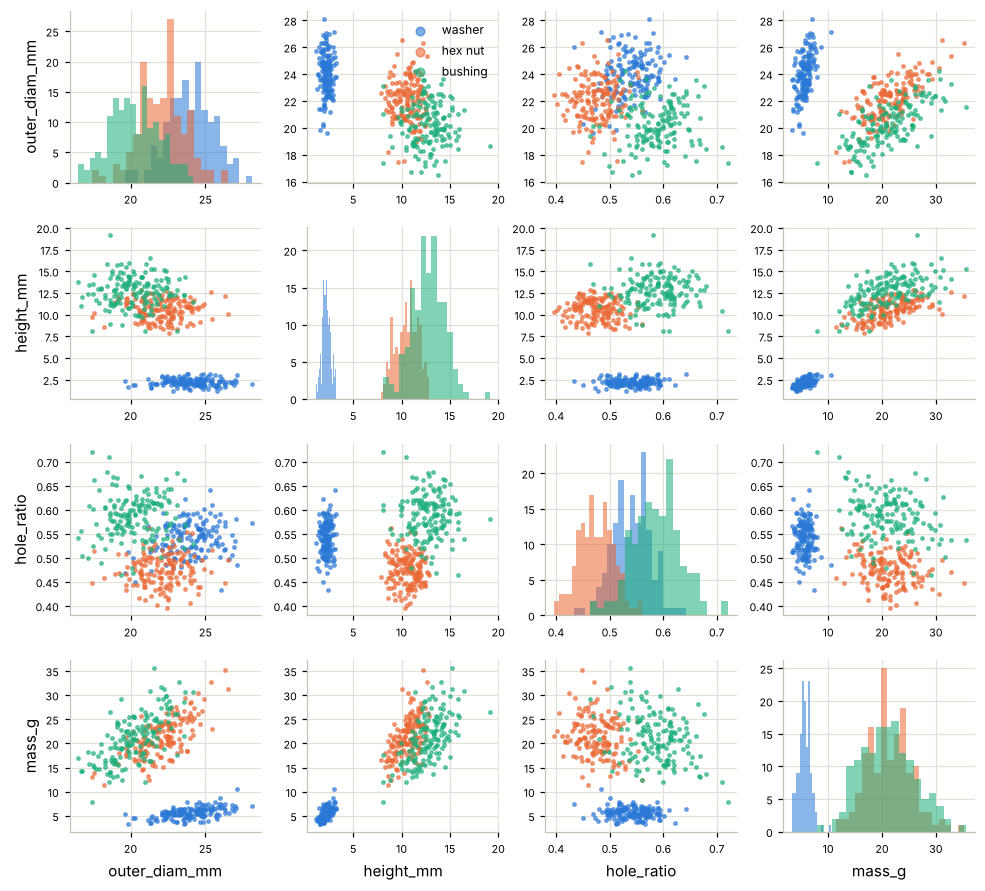

In [5]:
feat = ["outer_diam_mm", "height_mm", "hole_ratio", "mass_g"]
fig, axes = plt.subplots(4, 4, figsize=(9, 8.2))
for i, fi in enumerate(feat):
    for j, fj in enumerate(feat):
        ax = axes[i, j]
        for c in range(3):
            v = df[df.part == c]
            if i == j:
                ax.hist(v[fi], bins=20, color=CLASS_COLORS[c], alpha=0.55)
            else:
                ax.scatter(v[fj], v[fi], s=5, color=CLASS_COLORS[c], alpha=0.6,
                           label=PART_NAMES[c])
        if i == 3: ax.set_xlabel(fj)
        if j == 0: ax.set_ylabel(fi)
        ax.tick_params(labelsize=7)
axes[0, 1].legend(fontsize=8, markerscale=2.5, loc="upper right")
plt.tight_layout(); savefig("ch02_scatter_matrix"); plt.show()

---
## 2. Split first, then scale — with statistics from the training set only

Two rules that every chapter of this book follows:

1. **Hold out a test set before looking for patterns.** `stratify=y` keeps the class
   proportions identical in the training and test sets.
2. **Fit the scaler on the training set only**, then apply the *same* transformation to the
   test set. Using test-set statistics leaks information about data the model is supposed to
   have never seen. On the real cell, the scaler you ship is the one you fitted in the lab.

Standardisation puts every feature on the scale "number of standard deviations from the mean":
$$x'_j = \frac{x_j - \mu_j}{\sigma_j}.$$
Without it, `mass_g` (values around 20) and `hole_ratio` (values around 0.5) live on scales that
differ by a factor of 40 — which wrecks gradient descent, SVMs and k-NN alike (we will *see* the
damage in §6).

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[feat].to_numpy()
y = df["part"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

sc = StandardScaler().fit(X_train)          # statistics from the TRAINING set only
X_train_std, X_test_std = sc.transform(X_train), sc.transform(X_test)

print("class counts  all  :", np.bincount(y))
print("class counts  train:", np.bincount(y_train))
print("class counts  test :", np.bincount(y_test))
print("train means after scaling:", X_train_std.mean(axis=0).round(3))
print("test  means after scaling:", X_test_std.mean(axis=0).round(3), "<- close to 0, not exactly")

# two-feature views used for every decision-region plot in this chapter
IDX2 = [feat.index("height_mm"), feat.index("mass_g")]
X2_train, X2_test = X_train_std[:, IDX2], X_test_std[:, IDX2]
X2_comb = np.vstack([X2_train, X2_test]); y_comb = np.hstack([y_train, y_test])
test_idx = range(len(y_train), len(y_comb))
LAB2 = dict(xlabel="height (standardised)", ylabel="mass (standardised)")

class counts  all  : [150 150 150]
class counts  train: [105 105 105]
class counts  test : [45 45 45]
train means after scaling: [-0. -0. -0.  0.]
test  means after scaling: [ 0.031 -0.007  0.089  0.01 ] <- close to 0, not exactly


---
## 3. Logistic regression

### 3.1 The model

Logistic regression computes a weighted sum of the features — the **net input** —
$$z = \mathbf w^\top \mathbf x + b,$$
and squeezes it through the **logistic sigmoid**
$$\sigma(z) = \frac{1}{1+e^{-z}} \in (0,1).$$
The output is read as the probability that the part belongs to the positive class,
$\hat p = P(y=1\mid\mathbf x)$. The diverter fires for class 1 when $\hat p \ge 0.5$, i.e. when
$z \ge 0$: the decision boundary $\mathbf w^\top\mathbf x + b = 0$ is a **straight line** (a
hyperplane in more dimensions).

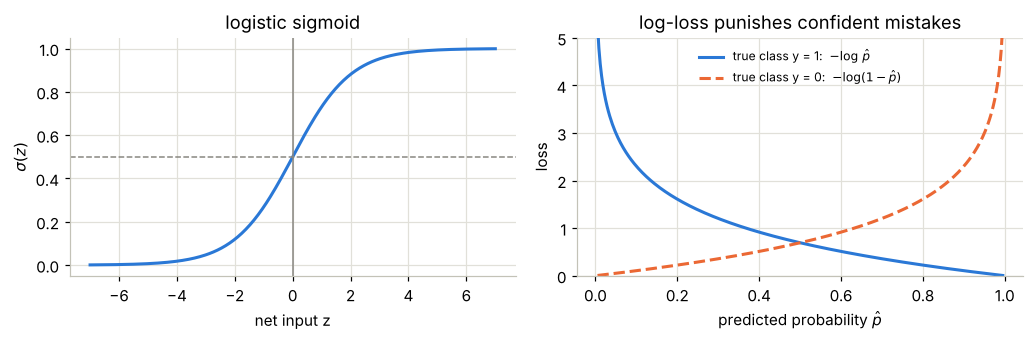

In [7]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -250, 250)))

z = np.linspace(-7, 7, 300)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
ax[0].plot(z, sigmoid(z), color=BLUE, lw=2)
ax[0].axhline(0.5, color=MUTED, ls="--", lw=1); ax[0].axvline(0, color=MUTED, lw=1)
ax[0].set_xlabel("net input z"); ax[0].set_ylabel(r"$\sigma(z)$"); ax[0].set_title("logistic sigmoid")
p = np.linspace(0.005, 0.995, 300)
ax[1].plot(p, -np.log(p), color=BLUE, lw=2, label="true class y = 1:  $-\\log\\,\\hat p$")
ax[1].plot(p, -np.log(1 - p), color=ORANGE, lw=2, ls="--", label="true class y = 0:  $-\\log(1-\\hat p)$")
ax[1].set_xlabel(r"predicted probability $\hat p$"); ax[1].set_ylabel("loss"); ax[1].set_ylim(0, 5)
ax[1].set_title("log-loss punishes confident mistakes"); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("ch02_sigmoid_logloss"); plt.show()

### 3.2 Learning the weights

Maximising the likelihood of the training labels is the same as minimising the average
**log-loss** (binary cross-entropy)
$$L(\mathbf w,b) = -\frac1n\sum_{i=1}^n\Big[y^{(i)}\log\hat p^{(i)} + (1-y^{(i)})\log(1-\hat p^{(i)})\Big].$$
Its gradient has a remarkably simple form — the error times the input:
$$\frac{\partial L}{\partial \mathbf w} = -\frac1n\sum_i \big(y^{(i)}-\hat p^{(i)}\big)\mathbf x^{(i)},\qquad
\frac{\partial L}{\partial b} = -\frac1n\sum_i \big(y^{(i)}-\hat p^{(i)}\big).$$
Gradient descent repeats $\mathbf w \leftarrow \mathbf w - \eta\,\partial L/\partial\mathbf w$
with learning rate $\eta$. Below is a complete implementation in about twenty lines.

In [8]:
class LogisticRegressionGD:
    """Binary logistic regression trained with full-batch gradient descent."""

    def __init__(self, eta=0.1, n_iter=1000, random_state=1):
        self.eta, self.n_iter, self.random_state = eta, n_iter, random_state

    def fit(self, X, y):
        rgen = np.random.default_rng(self.random_state)
        self.w_ = rgen.normal(0.0, 0.01, X.shape[1])
        self.b_ = 0.0
        self.losses_ = []
        for _ in range(self.n_iter):
            p = self.predict_proba(X)
            err = y - p
            self.w_ += self.eta * X.T @ err / len(y)
            self.b_ += self.eta * err.mean()
            eps = 1e-12
            self.losses_.append(-np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))
        return self

    def predict_proba(self, X):
        return sigmoid(X @ self.w_ + self.b_)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

We start with the hard binary sub-problem: **hex nut (0) vs bushing (1)**, using height and mass.

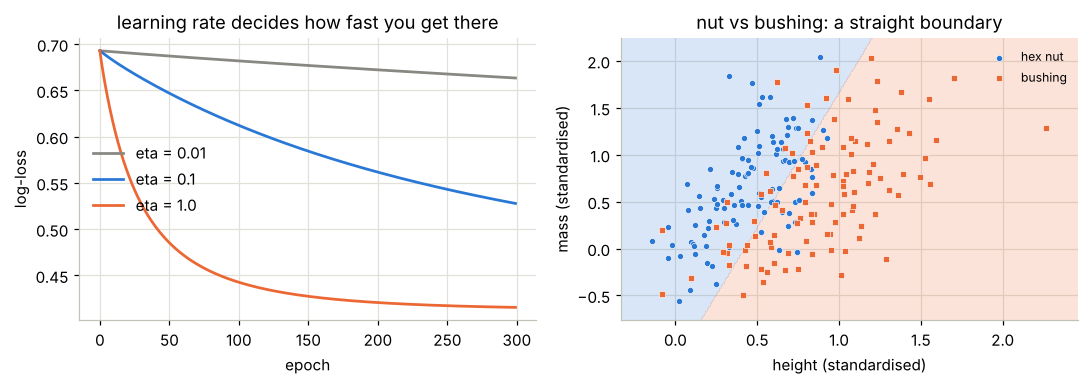

weights: [ 6.442 -2.239]  bias: -2.719
train accuracy 0.814   test accuracy 0.811


In [9]:
m_tr = y_train > 0
Xnb, ynb = X2_train[m_tr], (y_train[m_tr] == 2).astype(int)       # 1 = bushing
m_te = y_test > 0
Xnb_te, ynb_te = X2_test[m_te], (y_test[m_te] == 2).astype(int)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for eta, col in [(0.01, MUTED), (0.1, BLUE), (1.0, ORANGE)]:
    lr_gd = LogisticRegressionGD(eta=eta, n_iter=300).fit(Xnb, ynb)
    ax[0].plot(lr_gd.losses_, color=col, lw=1.8, label=f"eta = {eta}")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("log-loss"); ax[0].legend()
ax[0].set_title("learning rate decides how fast you get there")

lr_gd = LogisticRegressionGD(eta=0.5, n_iter=1000).fit(Xnb, ynb)
plot_decision_regions(Xnb, ynb, lr_gd, ax=ax[1], names=["hex nut", "bushing"], **LAB2)
ax[1].set_title("nut vs bushing: a straight boundary"); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("ch02_logreg_gd"); plt.show()

print("weights:", lr_gd.w_.round(3), " bias:", round(lr_gd.b_, 3))
print(f"train accuracy {np.mean(lr_gd.predict(Xnb) == ynb):.3f}   "
      f"test accuracy {np.mean(lr_gd.predict(Xnb_te) == ynb_te):.3f}")

**Reading the weights.** Height has a large positive weight (taller → more likely a bushing);
mass has a negative one — at a *given* height, a heavier part is more likely the solid hex nut.
Neither feature alone separates the two, which is why the boundary is tilted.

About one part in five is still mis-sorted: these two features simply overlap. The probability
output tells you *which* parts are uncertain, which is what a real cell needs — parts with
$0.3 < \hat p < 0.7$ can be sent to a reject lane for a second look instead of the wrong bin.

In [10]:
p_te = lr_gd.predict_proba(Xnb_te)
unsure = (p_te > 0.3) & (p_te < 0.7)
print(f"{unsure.mean():.0%} of test parts fall in the 'unsure' band")
print(f"accuracy on the confident ones: {np.mean(lr_gd.predict(Xnb_te[~unsure]) == ynb_te[~unsure]):.3f}")
print(f"accuracy on the unsure ones   : {np.mean(lr_gd.predict(Xnb_te[unsure]) == ynb_te[unsure]):.3f}")

28% of test parts fall in the 'unsure' band
accuracy on the confident ones: 0.954
accuracy on the unsure ones   : 0.440


### 3.3 Three classes with scikit-learn

`sklearn.linear_model.LogisticRegression` handles all three classes at once with the
**softmax** (multinomial) generalisation: one weight vector per class, and
$$P(y=k\mid\mathbf x) = \frac{e^{z_k}}{\sum_j e^{z_j}}.$$
It also adds **L2 regularisation** by default, controlled by `C` (the *inverse* regularisation
strength: small `C` = strong penalty on large weights).

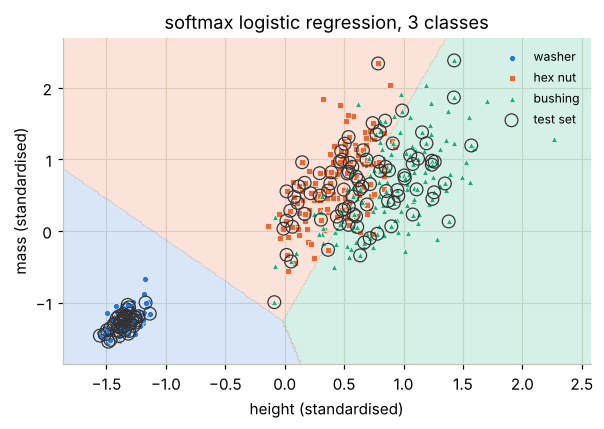

test accuracy (2 features): 0.874

class probabilities for the first three test parts:
   washer  hex nut  bushing
0     0.0    0.984    0.016
1     0.0    0.081    0.919
2     0.0    0.956    0.044
true labels: ['hex nut', 'bushing', 'hex nut']


In [11]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(C=100.0, random_state=1).fit(X2_train, y_train)

fig, ax = plt.subplots(figsize=(5.6, 4))
plot_decision_regions(X2_comb, y_comb, lr, ax=ax, names=PART_NAMES, test_idx=test_idx, **LAB2)
ax.set_title("softmax logistic regression, 3 classes"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("ch02_logreg_3class"); plt.show()

print("test accuracy (2 features):", round(lr.score(X2_test, y_test), 3))
print("\nclass probabilities for the first three test parts:")
print(pd.DataFrame(lr.predict_proba(X2_test[:3]), columns=PART_NAMES).round(3))
print("true labels:", [PART_NAMES[k] for k in y_test[:3]])

### 3.4 Regularisation path

Shrinking `C` pulls every weight toward zero. Plotting the weights against `C` — here using all
four features — shows which features the model leans on when it is forced to be frugal.

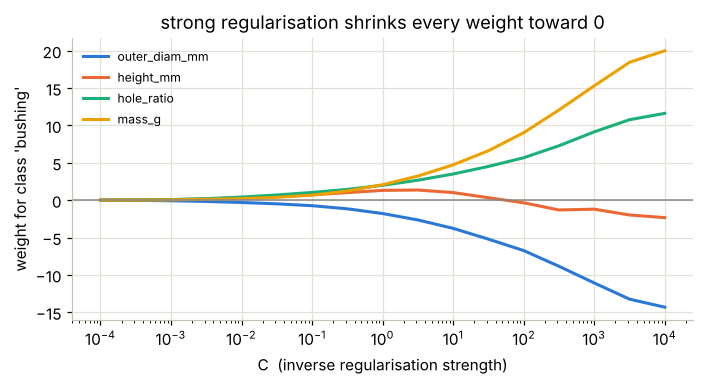

test accuracy, all four features: 0.993


In [12]:
Cs = 10.0 ** np.arange(-4, 4.5, 0.5)
W = np.array([LogisticRegression(C=c).fit(X_train_std, y_train).coef_[2] for c in Cs])  # bushing row

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for j, (f, col) in enumerate(zip(feat, [BLUE, ORANGE, AQUA, YELLOW])):
    ax.plot(Cs, W[:, j], color=col, lw=2, label=f)
ax.axhline(0, color=MUTED, lw=1); ax.set_xscale("log")
ax.set_xlabel("C  (inverse regularisation strength)"); ax.set_ylabel("weight for class 'bushing'")
ax.legend(fontsize=8); ax.set_title("strong regularisation shrinks every weight toward 0")
plt.tight_layout(); savefig("ch02_reg_path"); plt.show()

lr4 = LogisticRegression(C=10.0).fit(X_train_std, y_train)
print("test accuracy, all four features:", round(lr4.score(X_test_std, y_test), 3))

With all four features the accuracy jumps: `hole_ratio` is exactly the measurement that
separates a nut (small hole) from a bushing (big hole). **Feature choice beat model choice** —
a lesson that comes back in every chapter.

---
## 4. Support vector machines

### 4.1 Maximum margin

Many lines separate two classes. The SVM picks the one with the **widest margin** — the largest
distance to the closest training points, the *support vectors*. For separable data with labels
$y\in\{-1,+1\}$ this is
$$\min_{\mathbf w,b}\ \tfrac12\lVert\mathbf w\rVert^2\quad\text{s.t.}\quad y^{(i)}(\mathbf w^\top\mathbf x^{(i)}+b)\ge 1 .$$
Real data overlaps, so the **soft-margin** SVM allows violations $\xi_i\ge0$ at a price $C$:
$$\min\ \tfrac12\lVert\mathbf w\rVert^2 + C\sum_i\xi_i .$$
Large `C`: few violations, narrow margin (risk of overfitting). Small `C`: wide margin, more
training errors tolerated.

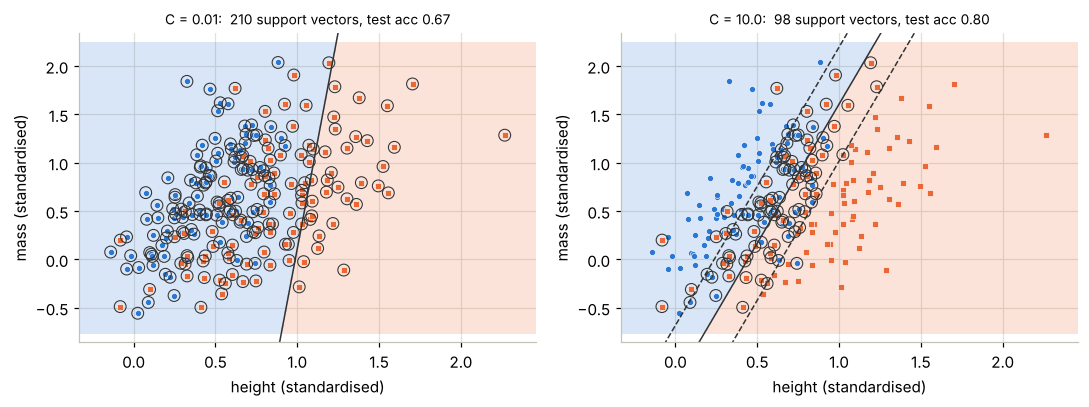

In [13]:
from sklearn.svm import SVC

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, C in zip(axes, [0.01, 10.0]):
    svm = SVC(kernel="linear", C=C).fit(Xnb, ynb)
    plot_decision_regions(Xnb, ynb, svm, ax=ax, names=["hex nut", "bushing"], **LAB2)
    # margin lines  w.x + b = +-1
    w, b = svm.coef_[0], svm.intercept_[0]
    xs = np.linspace(*ax.get_xlim(), 50)
    for off, ls in [(0, "-"), (1, "--"), (-1, "--")]:
        ax.plot(xs, (off - b - w[0] * xs) / w[1], color="#333", ls=ls, lw=1)
    ax.scatter(*svm.support_vectors_.T, s=60, facecolor="none", edgecolor="#333", lw=0.7)
    ax.set_ylim(Xnb[:, 1].min() - 0.3, Xnb[:, 1].max() + 0.3)
    ax.set_title(f"C = {C}:  {len(svm.support_)} support vectors, "
                 f"test acc {svm.score(Xnb_te, ynb_te):.2f}", fontsize=9)
plt.tight_layout(); savefig("ch02_svm_margin"); plt.show()

Circled points are support vectors: only they define the boundary. With very small `C` the
penalty on violations is so weak that the margin swallows almost every training point; the
boundary is then set by the bulk of the data rather than by the overlap region, and it lands in
the wrong place (it tilts toward "height only"). With `C = 10` the margin (dashed) is narrower,
about half the points are support vectors, and the boundary agrees with logistic regression.
Neither setting is "right" in general — `C` is a hyperparameter to tune (Chapter 6).

### 4.2 When no straight line works: the reachable workspace of a robot arm

A planar 2-link arm with link lengths $L_1 = 0.40$ m and $L_2 = 0.25$ m can reach a target point
only if its distance $r$ from the base satisfies $|L_1-L_2| \le r \le L_1+L_2$ — an **annulus**.
We ask a classifier to learn "reachable / not reachable" from $(x, y)$ samples, with a few
labels flipped near the boundary (encoder calibration error). No line separates a ring from its
inside and outside.

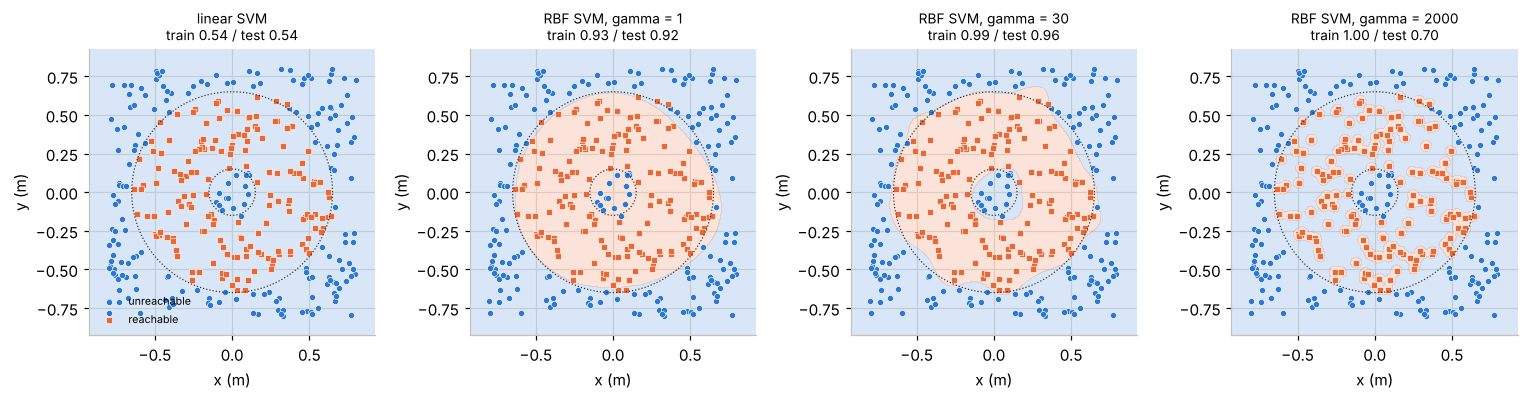

In [14]:
L1, L2 = 0.40, 0.25

def make_reach_dataset(n=500, seed=5):
    rng = np.random.default_rng(seed)
    P = rng.uniform(-0.8, 0.8, (n, 2))
    r = np.hypot(P[:, 0], P[:, 1])
    r_noisy = r + rng.normal(0, 0.015, n)          # calibration error near the edges
    reach = ((r_noisy >= abs(L1 - L2)) & (r_noisy <= L1 + L2)).astype(int)
    return P, reach

P, reach = make_reach_dataset()
P_tr, P_te, r_tr, r_te = train_test_split(P, reach, test_size=0.3, stratify=reach, random_state=1)

models = [("linear SVM", SVC(kernel="linear", C=1.0)),
          ("RBF SVM, gamma = 1", SVC(kernel="rbf", gamma=1.0, C=10.0)),
          ("RBF SVM, gamma = 30", SVC(kernel="rbf", gamma=30.0, C=10.0)),
          ("RBF SVM, gamma = 2000", SVC(kernel="rbf", gamma=2000.0, C=10.0))]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.9))
for ax, (name, mdl) in zip(axes, models):
    mdl.fit(P_tr, r_tr)
    plot_decision_regions(P_tr, r_tr, mdl, ax=ax, names=["unreachable", "reachable"],
                          xlabel="x (m)", ylabel="y (m)")
    t = np.linspace(0, 2 * np.pi, 200)
    for R in (L1 - L2, L1 + L2):
        ax.plot(R * np.cos(t), R * np.sin(t), color="#333", lw=0.8, ls=":")
    ax.set_aspect("equal")
    ax.set_title(f"{name}\ntrain {mdl.score(P_tr, r_tr):.2f} / test {mdl.score(P_te, r_te):.2f}", fontsize=9)
axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); savefig("ch02_svm_workspace"); plt.show()

### 4.3 The kernel trick

The RBF SVM never computes new features explicitly. It replaces every dot product
$\mathbf x^{(i)\top}\mathbf x^{(j)}$ in the SVM's dual problem with a **kernel**
$$k(\mathbf x^{(i)},\mathbf x^{(j)}) = \exp\!\big(-\gamma\lVert\mathbf x^{(i)}-\mathbf x^{(j)}\rVert^2\big),$$
which is a dot product in an (infinite-dimensional) feature space. In that space the ring *is*
linearly separable. A tiny illustration: add the single feature $r^2 = x^2+y^2$ and the ring
becomes a horizontal slab — two thresholds on one axis.

`gamma` sets the reach of each training point. **Small gamma** (γ = 1) → a very smooth
boundary that cannot quite bend tightly enough around the small inner hole. **Moderate gamma**
(γ = 30) → close to the true annulus. **Very large gamma** (γ = 2000) → every training point gets
its own little island; training accuracy is perfect and the test accuracy collapses — textbook
**overfitting**.

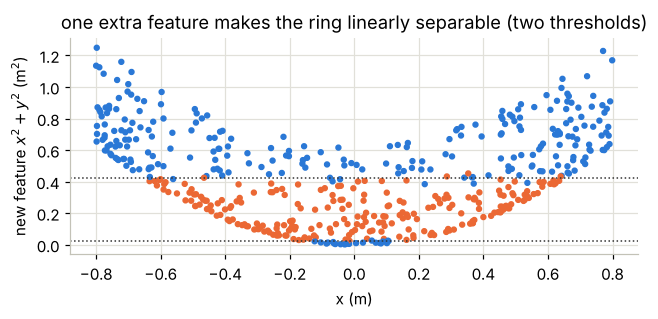

In [15]:
fig, ax = plt.subplots(figsize=(6, 3))
r2 = (P ** 2).sum(axis=1)
ax.scatter(P[:, 0], r2, c=[CLASS_COLORS[k] for k in reach], s=10)
for R in (L1 - L2, L1 + L2):
    ax.axhline(R ** 2, color="#333", ls=":", lw=1)
ax.set_xlabel("x (m)"); ax.set_ylabel(r"new feature $x^2+y^2$ (m$^2$)")
ax.set_title("one extra feature makes the ring linearly separable (two thresholds)")
plt.tight_layout(); savefig("ch02_kernel_lift"); plt.show()

---
## 5. Decision trees

A decision tree asks a sequence of yes/no questions — *"is height ≤ 5.8 mm?"* — and is the
classifier a PLC programmer would write by hand. The learning algorithm chooses each question to
make the two resulting groups as **pure** as possible.

### 5.1 Impurity and information gain

For a node $t$ where class $k$ has proportion $p_k$:

| measure | formula |
|---|---|
| entropy | $I_H(t) = -\sum_k p_k\log_2 p_k$ |
| Gini impurity | $I_G(t) = 1 - \sum_k p_k^2$ |
| classification error | $I_E(t) = 1 - \max_k p_k$ |

A split of parent $D_p$ into children $D_\text{left}, D_\text{right}$ is scored by the
**information gain**
$$IG = I(D_p) - \frac{N_\text{left}}{N_p}I(D_\text{left}) - \frac{N_\text{right}}{N_p}I(D_\text{right}).$$
The tree greedily takes the split with the largest gain at each node.

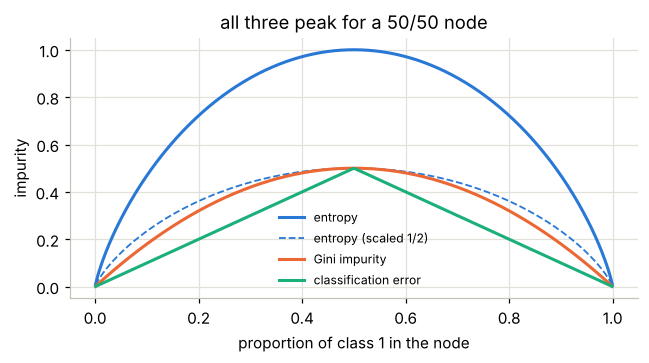

In [16]:
p = np.linspace(0.001, 0.999, 300)
ent = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
gini = 1 - (p ** 2 + (1 - p) ** 2)
err = 1 - np.maximum(p, 1 - p)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(p, ent, color=BLUE, lw=2, label="entropy")
ax.plot(p, ent / 2, color=BLUE, lw=1.2, ls="--", label="entropy (scaled 1/2)")
ax.plot(p, gini, color=ORANGE, lw=2, label="Gini impurity")
ax.plot(p, err, color=AQUA, lw=2, label="classification error")
ax.set_xlabel("proportion of class 1 in the node"); ax.set_ylabel("impurity")
ax.legend(fontsize=8); ax.set_title("all three peak for a 50/50 node")
plt.tight_layout(); savefig("ch02_impurity"); plt.show()

Trees do **not** need feature scaling — a threshold on raw millimetres is as good as one on
standardised units — so we train on the raw height and mass and get rules in engineering units.

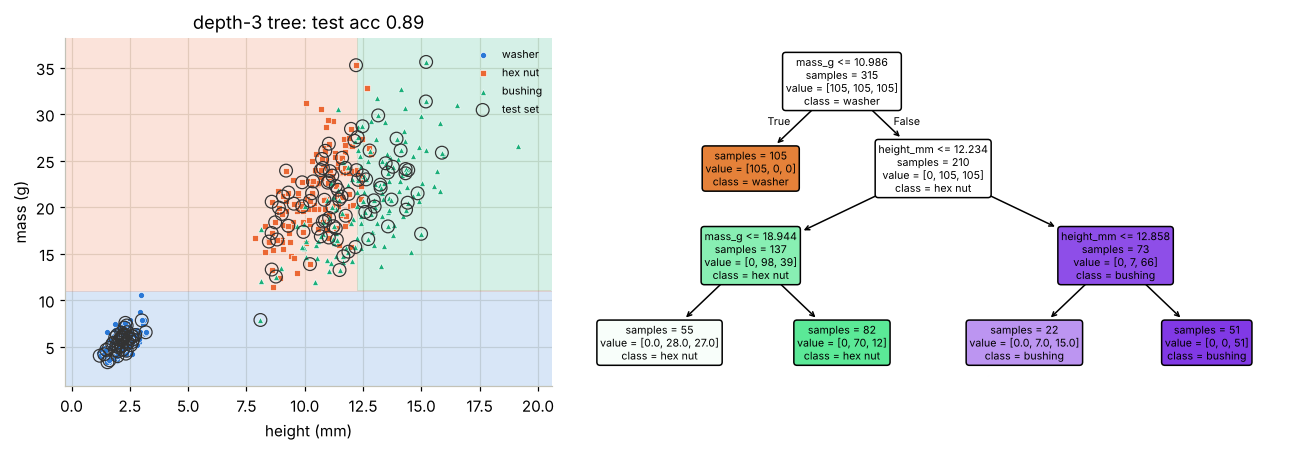

In [17]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

X2raw_tr, X2raw_te = X_train[:, IDX2], X_test[:, IDX2]
tree = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=1).fit(X2raw_tr, y_train)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1, 1.5]))
plot_decision_regions(np.vstack([X2raw_tr, X2raw_te]), y_comb, tree, ax=ax[0], names=PART_NAMES,
                      test_idx=test_idx, xlabel="height (mm)", ylabel="mass (g)")
ax[0].legend(fontsize=7); ax[0].set_title(f"depth-3 tree: test acc {tree.score(X2raw_te, y_test):.2f}")
plot_tree(tree, feature_names=["height_mm", "mass_g"], class_names=PART_NAMES,
          filled=True, rounded=True, fontsize=7, ax=ax[1], impurity=False)
plt.tight_layout(); savefig("ch02_tree"); plt.show()

The first split, on mass (≤ 11 g), isolates every washer in one question — height would have
done the job equally well, and the tree picked whichever came first among equally good splits. The remaining splits carve
axis-parallel rectangles out of the nut/bushing overlap. **Axis-parallel** is the defining
feature of a tree's boundary — compare it with the tilted line of logistic regression.

### 5.2 Depth controls complexity

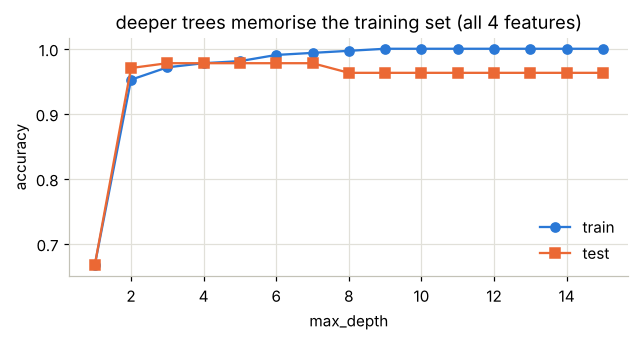

mass_g           0.533
hole_ratio       0.394
height_mm        0.046
outer_diam_mm    0.028
dtype: float64


In [18]:
depths = range(1, 16)
tr_acc, te_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=1).fit(X_train, y_train)
    tr_acc.append(t.score(X_train, y_train)); te_acc.append(t.score(X_test, y_test))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(depths, tr_acc, "o-", color=BLUE, label="train"); ax.plot(depths, te_acc, "s-", color=ORANGE, label="test")
ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy"); ax.legend()
ax.set_title("deeper trees memorise the training set (all 4 features)")
plt.tight_layout(); savefig("ch02_tree_depth"); plt.show()

tree4 = DecisionTreeClassifier(max_depth=4, random_state=1).fit(X_train, y_train)
print(pd.Series(tree4.feature_importances_, index=feat).sort_values(ascending=False).round(3))

A single tree is unstable: change a few training samples and the splits can change completely.
Averaging many randomised trees — a **random forest** — fixes that. That is the topic of
Chapter 4.

---
## 6. k-nearest neighbours

k-NN does no training at all. To classify a new part it finds the $k$ closest training parts
and takes a majority vote. All the modelling lives in two choices: **$k$** and **the distance**.

The default distance is Euclidean, so a feature measured in large numbers dominates. Below, the
same k-NN is trained on raw features (mass in grams spans ~25 units, hole ratio ~0.3 units) and
on standardised features.

k-NN on raw features         : test accuracy 0.874
k-NN on standardised features: test accuracy 0.993


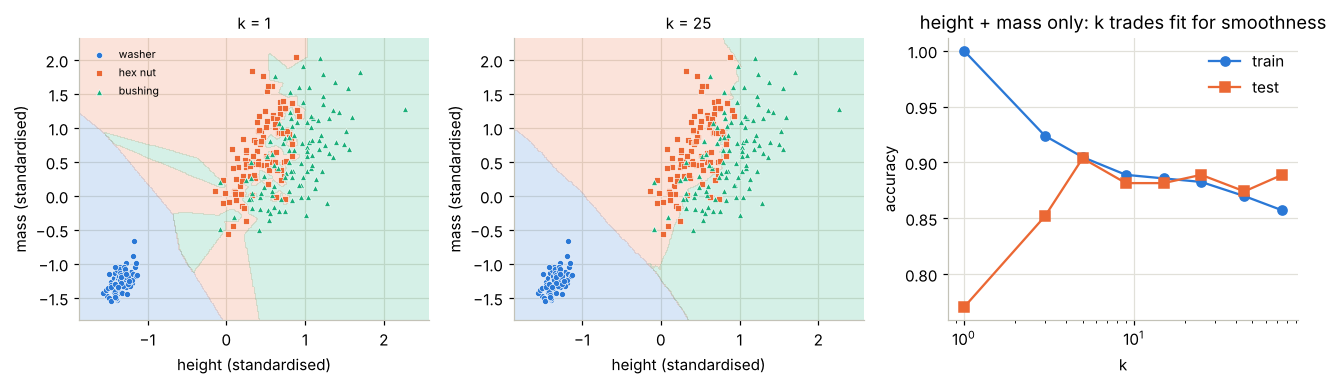

In [19]:
from sklearn.neighbors import KNeighborsClassifier

knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
knn_std = KNeighborsClassifier(n_neighbors=5).fit(X_train_std, y_train)
print(f"k-NN on raw features         : test accuracy {knn_raw.score(X_test, y_test):.3f}")
print(f"k-NN on standardised features: test accuracy {knn_std.score(X_test_std, y_test):.3f}")

ks = [1, 3, 5, 9, 15, 25, 45, 75]
# the k sweep uses the harder 2-feature view (height, mass), where the classes overlap
acc_tr = [KNeighborsClassifier(k).fit(X2_train, y_train).score(X2_train, y_train) for k in ks]
acc_te = [KNeighborsClassifier(k).fit(X2_train, y_train).score(X2_test, y_test) for k in ks]

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, k in zip(ax[:2], [1, 25]):
    mdl = KNeighborsClassifier(k).fit(X2_train, y_train)
    plot_decision_regions(X2_train, y_train, mdl, ax=a, names=PART_NAMES, **LAB2)
    a.set_title(f"k = {k}", fontsize=10)
ax[0].legend(fontsize=7)
ax[2].plot(ks, acc_tr, "o-", color=BLUE, label="train"); ax[2].plot(ks, acc_te, "s-", color=ORANGE, label="test")
ax[2].set_xscale("log"); ax[2].set_xlabel("k"); ax[2].set_ylabel("accuracy"); ax[2].legend()
ax[2].set_title("height + mass only: k trades fit for smoothness")
plt.tight_layout(); savefig("ch02_knn"); plt.show()

Two practical warnings for the shop floor:

* **Prediction cost grows with the data.** k-NN keeps every training sample and searches them
  at prediction time. With a 10 ms diverter window and millions of logged parts, that matters.
* **The curse of dimensionality.** With many features, "nearest" neighbours stop being near.
  Chapter 5 shows how to compress features before using distance-based methods.

---
## 7. Head-to-head

All four classifiers, all four features, the same split, the same test set. Scaling is put
inside a `Pipeline` so it is always fitted on whatever data the model is fitted on (Chapter 6
explains why that matters for cross-validation).

In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import time

candidates = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=10.0)),
    "linear SVM":          make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0)),
    "RBF SVM":             make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10.0, gamma=0.2)),
    "decision tree (d=4)": DecisionTreeClassifier(max_depth=4, random_state=1),
    "k-NN (k=9)":          make_pipeline(StandardScaler(), KNeighborsClassifier(9)),
}
rows = []
for name, mdl in candidates.items():
    mdl.fit(X_train, y_train)
    t0 = time.perf_counter(); 
    for _ in range(20): mdl.predict(X_test)
    t_pred = (time.perf_counter() - t0) / 20 / len(X_test) * 1e6
    rows.append(dict(model=name, train_acc=mdl.score(X_train, y_train),
                     test_acc=mdl.score(X_test, y_test), us_per_part=t_pred))
summary = pd.DataFrame(rows).set_index("model").round(3)
summary

,train_acc,test_acc,us_per_part
model,,,
logistic regression,0.994,0.993,1.892
linear SVM,0.990,0.993,2.741
RBF SVM,0.994,0.993,3.357
decision tree (d=4),0.978,0.978,0.732
k-NN (k=9),0.975,0.993,13.814


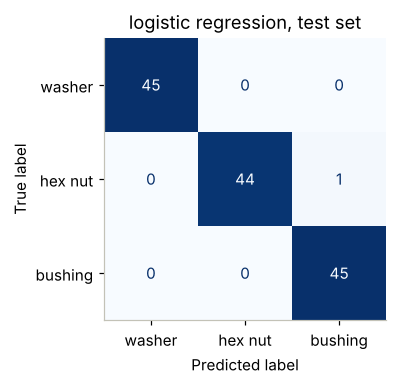

In [21]:
best = candidates["logistic regression"]
ConfusionMatrixDisplay(confusion_matrix(y_test, best.predict(X_test)),
                       display_labels=PART_NAMES).plot(cmap="Blues", colorbar=False)
plt.title("logistic regression, test set"); plt.grid(False)
plt.tight_layout(); savefig("ch02_confusion"); plt.show()

With the right four features **every model sorts almost perfectly**, and the remaining errors
are all nut ↔ bushing. The differences between models are smaller than the difference between
two features and four. On a production cell the deciding factors are then the ones the
accuracy table does not show: whether the operator can read the rule (tree), whether you get a
calibrated probability for a reject lane (logistic regression), and how prediction time scales
(k-NN).

---
## Summary

* A classifier is chosen as much by the **shape of boundary** it can draw as by its accuracy:
  linear (logistic regression, linear SVM), smooth curved (RBF SVM), axis-parallel boxes
  (tree), arbitrary but local (k-NN).
* **Scale** for anything that uses distances or gradients; fit the scaler on training data only.
* **Regularisation** (`C`, `gamma`, `max_depth`, `k`) trades training fit against generalisation.
  Choosing it properly needs cross-validation — Chapter 6.

## Exercises

1. Retrain the from-scratch `LogisticRegressionGD` on raw (unscaled) height and mass. What
   learning rate still converges? Explain using the shape of the loss surface.
2. Add `hole_ratio` to the 2-feature nut/bushing problem. How much does test accuracy improve?
   Which weight is now the largest?
3. Give the reachability problem a joint limit $0 \le q_2 \le 150^\circ$ (elbow-up only)
   and regenerate labels with inverse kinematics. Which `gamma` now works best?
4. Count how many training parts a depth-4 tree needs before the test accuracy stops improving
   (subsample the training set at 10 %, 20 %, … 100 %).
5. Replace the Euclidean distance in k-NN with Manhattan (`p=1`). Does it matter here? Why
   might it matter with 50 features?